# 01 · Khám phá bộ dữ liệu

Bộ dữ liệu **Vietnamese vehicle v3** (Roboflow, CC BY 4.0), nhãn đã chuẩn hoá từ 4 lớp gốc
(`car`, `motorbike`, `truck`, `bus`) về 3 lớp của đề tài: **xe con**, **xe tải** (gộp cả `bus`), **xe máy**.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# Notebook co the mo tu thu muc goc hoac tu notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
for p in (ROOT / "src", ROOT / "scripts"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import random
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

import make_figures as mf          # read_labels, draw_gt, hang so mau / ten lop
import prepare_dataset as prep     # check(): kiem tra dinh dang nhan + thong ke

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100})
print("Bo du lieu:", mf.DATASET.relative_to(ROOT), "| ton tai:", mf.DATASET.exists())

Bo du lieu: Data\Vietnamese vehicle.v3-2023-02-01-5-31pm.yolo26 | ton tai: True


## 1. Kiểm tra định dạng nhãn

`check()` duyệt mọi file nhãn: mỗi dòng phải có 5 giá trị, chỉ số lớp trong `0..2`, toạ độ trong `[0, 1]`.
Ảnh không có file nhãn là ảnh nền (không có xe).

In [2]:
ok = prep.check()
print("\n=> Nhan hop le" if ok else "\n=> CO LOI NHAN, xem cac dong LOI o tren")

split    anh  nhan       car     truck motorbike  tong box


train   1235  1235      2261      1745      1789      5795
valid    156   156       283       211       214       708
test     156   156       273       227       229       729
tong                    2817      2183      2232      7232
Kiem tra nhan: OK

=> Nhan hop le


## 2. Số ảnh và số box theo tập, theo lớp

In [3]:
rows = {}
for split, ten in mf.SPLITS.items():
    cnt, files = mf.read_labels(split)
    n_img = sum(1 for p in (mf.DATASET / split / "images").glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    rows[ten] = {"Số ảnh": n_img, **{mf.VI[i]: cnt[i] for i in range(3)}, "Tổng box": sum(cnt.values())}
df_split = pd.DataFrame(rows).T
df_split.loc["Tổng"] = df_split.sum()
df_split

,Số ảnh,Xe con,Xe tải,Xe máy,Tổng box
Huấn luyện,1235,2261,1745,1789,5795
Kiểm định,156,283,211,214,708
Kiểm thử,156,273,227,229,729
Tổng,1547,2817,2183,2232,7232


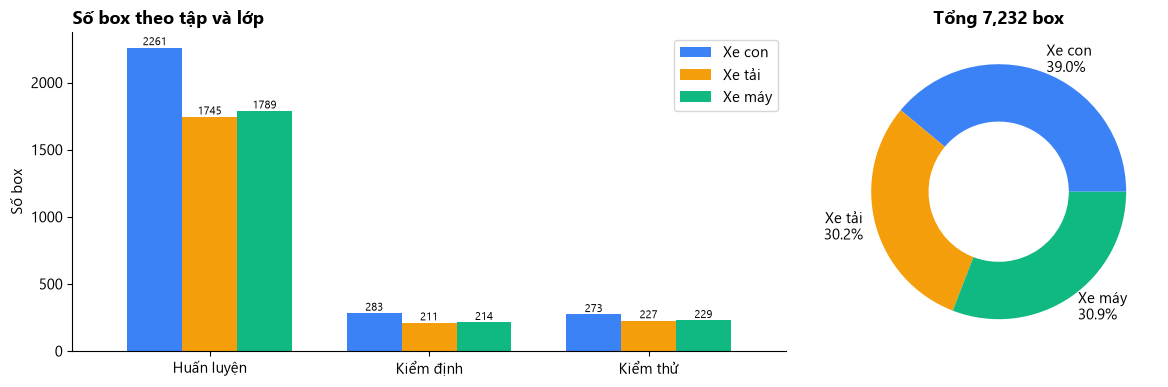

Ti le box theo lop (%): {'Xe con': 39.0, 'Xe tải': 30.2, 'Xe máy': 30.9}


In [4]:
tong_lop = df_split.loc["Tổng", mf.VI]
ti_le = (tong_lop / tong_lop.sum() * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1]})
df_split.drop("Tổng")[mf.VI].plot.bar(ax=axes[0], color=mf.COLORS, rot=0, width=0.75)
axes[0].set_ylabel("Số box"); axes[0].set_title("Số box theo tập và lớp", loc="left", weight="bold")
for c in axes[0].containers:
    axes[0].bar_label(c, fontsize=8)
axes[1].pie(tong_lop, labels=[f"{k}\n{v}%" for k, v in ti_le.items()], colors=mf.COLORS,
            wedgeprops=dict(width=0.45))
axes[1].set_title(f"Tổng {int(tong_lop.sum()):,} box", weight="bold")
plt.tight_layout(); plt.show()

print("Ti le box theo lop (%):", ti_le.to_dict())

**Đọc biểu đồ:** tỷ lệ in ở trên cho biết lớp nào chiếm đa số. Nếu một lớp quá ít box, mô hình dễ học kém
lớp đó. Ba tập train / valid / test có cùng phân bố lớp thì điểm trên tập test mới đại diện cho dữ liệu huấn luyện.

## 3. Mật độ xe và kích thước box

Đọc trực tiếp file nhãn YOLO (`lớp cx cy w h`, toạ độ chuẩn hoá theo kích thước ảnh).
Cạnh box tính bằng `sqrt(w·h)` × kích thước ảnh (640 px), để so sánh độ lớn của xe giữa các lớp.

So xe moi anh (anh co nhan):
count    1547.0
mean        4.7
std         3.1
min         1.0
25%         2.0
50%         4.0
75%         6.0
max        21.0


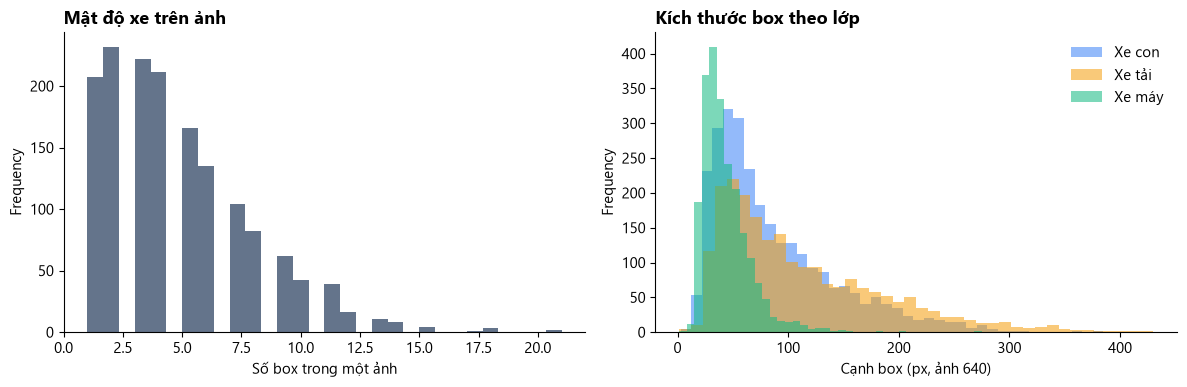

,count,mean,std,min,25%,50%,75%,max
lop,,,,,,,,
Xe con,2817.0,86.2,56.3,2.8,45.1,68.2,113.2,385.0
Xe máy,2232.0,43.5,21.9,1.4,28.6,38.2,53.4,275.1
Xe tải,2183.0,111.9,73.8,1.7,54.4,90.5,154.6,430.0


In [5]:
IMG = 640  # anh trong bo du lieu deu 640x640 (Roboflow export)
recs = []
for split in mf.SPLITS:
    _, files = mf.read_labels(split)
    for f in files:
        for ln in f.read_text(encoding="utf-8").splitlines():
            if ln.strip():
                c, cx, cy, w, h = ln.split()
                recs.append({"split": split, "file": f.stem, "lop": mf.VI[int(c)],
                             "canh_px": (float(w) * float(h)) ** 0.5 * IMG})
boxes = pd.DataFrame(recs)

per_img = boxes.groupby(["split", "file"]).size()
print("So xe moi anh (anh co nhan):")
print(per_img.describe().round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
per_img.plot.hist(bins=30, ax=axes[0], color="#64748B")
axes[0].set_xlabel("Số box trong một ảnh"); axes[0].set_title("Mật độ xe trên ảnh", loc="left", weight="bold")
for lop, color in zip(mf.VI, mf.COLORS):
    boxes.loc[boxes.lop == lop, "canh_px"].plot.hist(bins=40, ax=axes[1], alpha=0.55, color=color, label=lop)
axes[1].set_xlabel("Cạnh box (px, ảnh 640)"); axes[1].legend(frameon=False)
axes[1].set_title("Kích thước box theo lớp", loc="left", weight="bold")
plt.tight_layout(); plt.show()

boxes.groupby("lop")["canh_px"].describe(percentiles=[.25, .5, .75]).round(1)

**Ý nghĩa với bài toán:** box càng nhỏ thì chỉ cần lệch vài pixel là IoU giảm mạnh, nên lớp có cạnh box trung vị
nhỏ nhất sẽ bị ảnh hưởng nhiều nhất ở các ngưỡng IoU cao (mAP@0.5:0.95). Phân tích chi tiết ở notebook 02, mục AP theo
ngưỡng IoU, và ở báo cáo Tuần 4.

## 4. Ảnh mẫu kèm nhãn

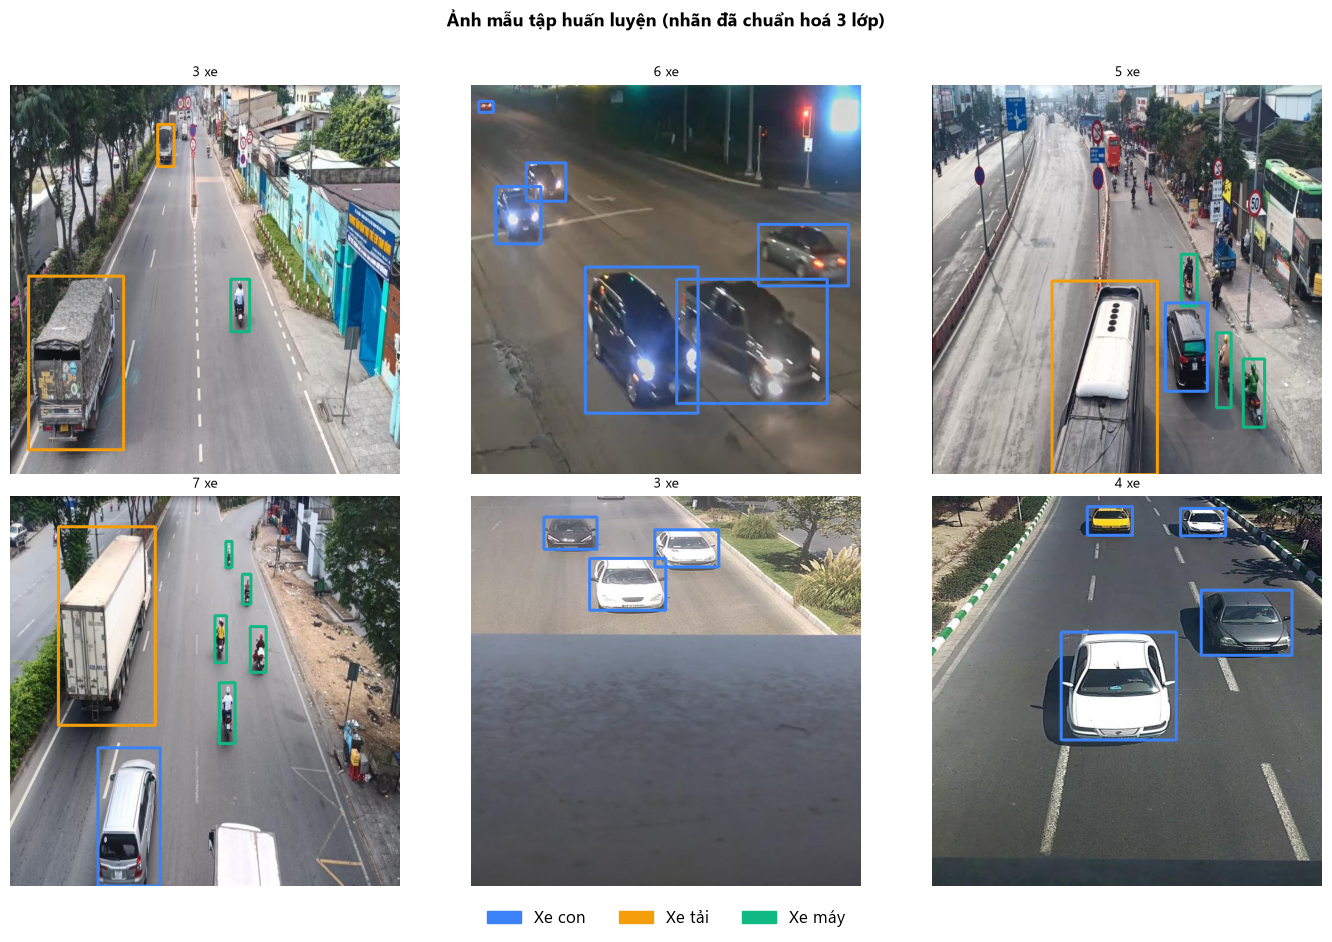

In [6]:
random.seed(7)
_, files = mf.read_labels("train")
picks = random.sample([f for f in files if len(f.read_text().splitlines()) >= 3], 6)

fig, axes = plt.subplots(2, 3, figsize=(14, 9.5))
for ax, lbl in zip(axes.flat, picks):
    img = next((mf.DATASET / "train" / "images").glob(lbl.stem + ".*"))
    ax.imshow(mf.draw_gt(img, lbl))
    ax.set_title(f"{len(lbl.read_text().splitlines())} xe", fontsize=10)
    ax.axis("off")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in mf.COLORS], mf.VI,
           loc="lower center", ncol=3, frameon=False, fontsize=12)
fig.suptitle("Ảnh mẫu tập huấn luyện (nhãn đã chuẩn hoá 3 lớp)", weight="bold")
plt.tight_layout(rect=(0, 0.04, 1, 0.97)); plt.show()